In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import plot_tree
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,root_mean_squared_error

In [2]:

url = "https://raw.githubusercontent.com/sinhabishal77/Kaggle-Bike-Sharing-Demand/master/train.csv"
bike_sale= pd.read_csv(url)
bike_sale.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [3]:
bike_sale.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  str    
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 1020.7 KB


In [4]:
bike_sale['datetime']=pd.to_datetime(bike_sale['datetime'])

In [5]:
bike_sale['datetime'].dtype

dtype('<M8[us]')

In [6]:
bike_sale['day']=bike_sale['datetime'].dt.day
bike_sale['year']=bike_sale['datetime'].dt.year
bike_sale['month']=bike_sale['datetime'].dt.month
bike_sale['hour'] = bike_sale['datetime'].dt.hour
bike_sale['dayofweek'] = bike_sale['datetime'].dt.dayofweek

In [7]:
print(bike_sale['day'])
print(bike_sale['year'])

0         1
1         1
2         1
3         1
4         1
         ..
10881    19
10882    19
10883    19
10884    19
10885    19
Name: day, Length: 10886, dtype: int32
0        2011
1        2011
2        2011
3        2011
4        2011
         ... 
10881    2012
10882    2012
10883    2012
10884    2012
10885    2012
Name: year, Length: 10886, dtype: int32


In [8]:
bike_sale.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,day,year,month,hour,dayofweek
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,1,2011,1,0,5
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1,2011,1,1,5
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,1,2011,1,2,5
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,1,2011,1,3,5
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,1,2011,1,4,5


In [9]:
bike_sale.isna().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
day           0
year          0
month         0
hour          0
dayofweek     0
dtype: int64

In [10]:
# 1. Clean-ana X and y features-ai iruka nu confirm panrathu
drop_cols = ['datetime', 'date', 'casual', 'registered', 'count']
existing_drops = [col for col in drop_cols if col in bike_sale.columns]

X = bike_sale.drop(columns=existing_drops)
y = bike_sale['count']

# 2. Fresh-a train and test split panrathu
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Model train panrathu
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 4. Predict 
y_pred = rf.predict(X_test)

In [11]:
feature=X.columns
impotance=rf.feature_importances_
important_feature=pd.DataFrame({'feature':feature,'important':impotance})


<BarContainer object of 13 artists>

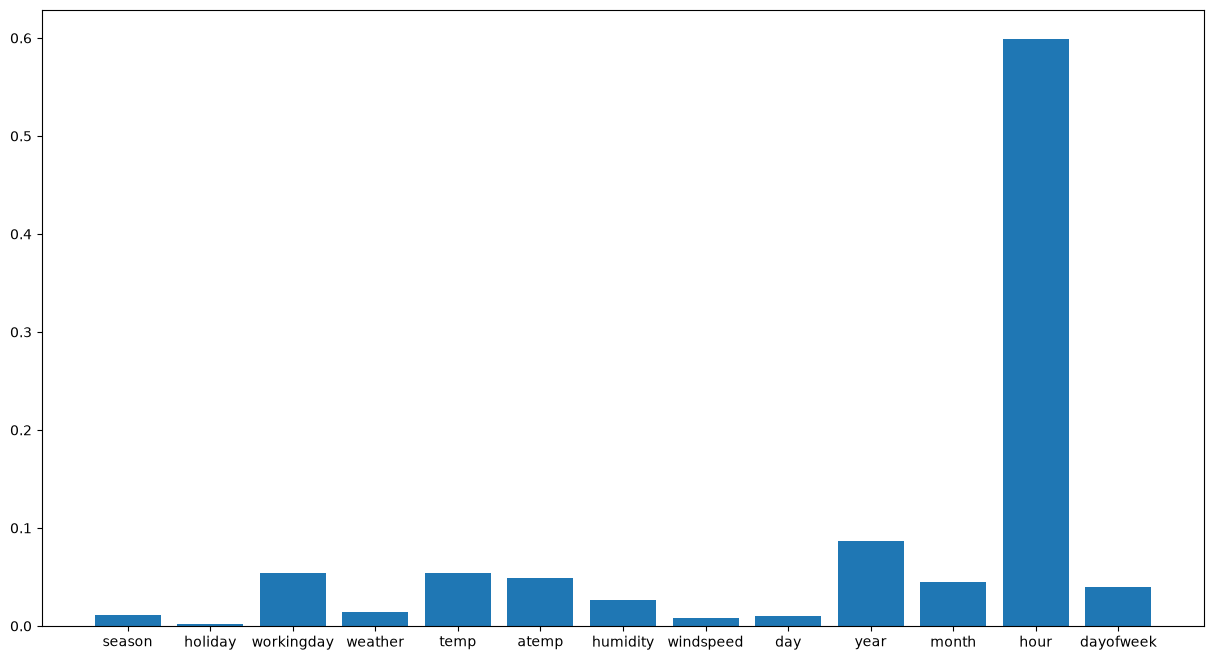

In [12]:
plt.figure(figsize=(15,8))
plt.bar(feature,impotance)

## model prediction

In [13]:
y_pred = rf.predict(X_test)

In [14]:
y_pred

array([141.14,  31.86, 160.  , ..., 467.83,   7.78, 158.16], shape=(2178,))

In [15]:
sample=X_test.iloc[0:1]
print(sample)
rf.predict(sample)

      season  holiday  workingday  weather   temp  atemp  humidity  windspeed  \
3133       3        0           1        1  33.62  40.15        59        0.0   

      day  year  month  hour  dayofweek  
3133   19  2011      7    11          1  


array([141.14])

In [16]:
sample_dict=sample.iloc[0].to_dict()
sample_dict

{'season': 3.0,
 'holiday': 0.0,
 'workingday': 1.0,
 'weather': 1.0,
 'temp': 33.62,
 'atemp': 40.15,
 'humidity': 59.0,
 'windspeed': 0.0,
 'day': 19.0,
 'year': 2011.0,
 'month': 7.0,
 'hour': 11.0,
 'dayofweek': 1.0}

In [17]:
rf.predict(sample)

array([141.14])

## evaluate the model

In [18]:
mean_absolute_error(y_test,y_pred)

24.28118916437098

In [19]:
mean_squared_error(y_test,y_pred)

1508.4237752525253

In [20]:
root_mean_squared_error(y_test,y_pred)

38.83843167859028

In [21]:
r2_score(y_test,y_pred)

0.9542997937942382

## plot the tree

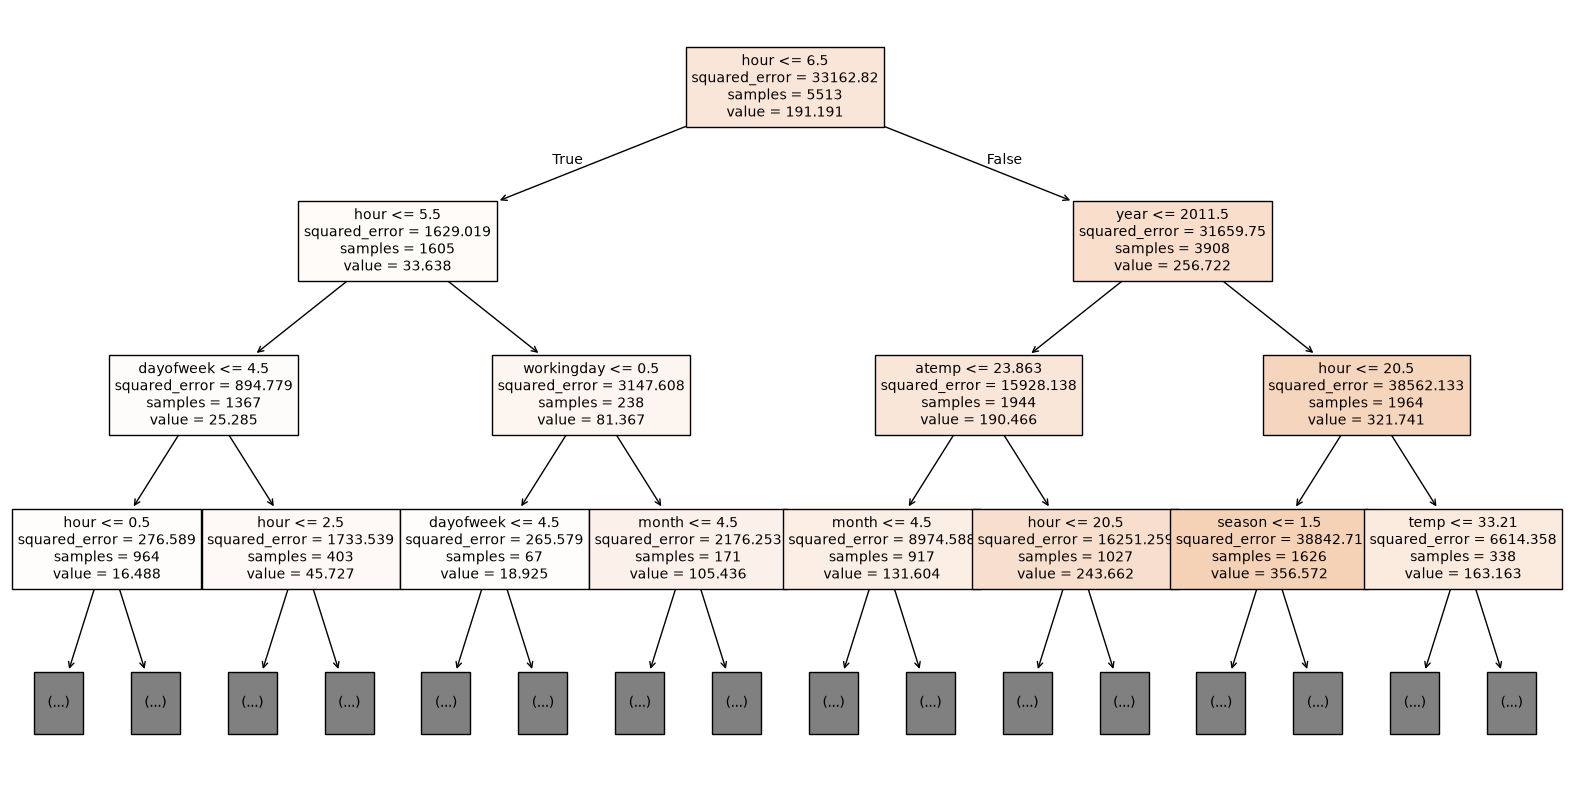

In [25]:
plt.figure(figsize=(20, 10))
plot_tree(
    rf.estimators_[0], 
    feature_names=X.columns, 
    max_depth=3,      # 3 levels மட்டும் காட்டும்
    filled=True,      # அழகான வண்ணங்கள் தரும்
    fontsize=10       # Font size தெளிவாக இருக்கும்
)
plt.show()